# Домашнее задание № 1

**Тема:** Обнаружение вредоносных Android-приложений


## 1. Постановка задачи

### Бизнес-задача

На Android можно установить как безопасное, так и вредоносное приложение. Некоторые вредоносные программы получают доступ к SMS, контактам и другим данным пользователя.

**Цель:** создать модель, которая по разрешениям Android-приложения будет определять, является оно вредоносным или безопасным. Это может помочь специалистам быстрее находить подозрительные приложения и отправлять их на дополнительную проверку.

### Задача машинного обучения

Это задача **бинарной классификации**, потому что возможны два класса:

- 0 - безопасное приложение
- 1 - вредоносное приложение

Каждая строка таблицы соответствует одному приложению. Признаки - разрешения, которые оно запрашивает. В столбцах с разрешениями **1** означает, что приложение запрашивает разрешение, а **0** - не запрашивает.

Наша целевая переменная - столбец **Result**.

###  Набор данных

Используем открытый набор данных NATICUSdroid (Android Permissions) из UCI Machine Learning Repository.

В нём около 29 тысяч приложений и 86 признаков-разрешений. Данные относятся к приложениям, собранным за 2010–2019 годы.

**Источник:** https://archive.ics.uci.edu/dataset/722/naticusdroid+android+permissions+dataset

Этого количества данных достаточно для нашей задачи бинарной классификации. Но по одним разрешениям нельзя со стопроцентной уверенностью определить, опасно ли приложение: некоторые разрешения нужны и обычным программам.

## 2. Выбор метрик качества

Будущая модель может допустить две основные ошибки:

1. Не заметить вредоносное приложение и посчитать его безопасным. Тогда пользователь может установить опасную программу.
2. Посчитать безопасное приложение вредоносным. Тогда приложение придётся проверить дополнительно.

Для нашей задачи первая ошибка более серьёзная, поэтому особенно важно находить как можно больше вредоносных приложений.

Среди метрик выберем:

- **Recall (полнота)** - какую долю всех вредоносных приложений модель смогла найти.
- **Precision (точность)** - какая доля приложений, названных вредоносными, действительно вредоносная.
- **F2-score** - общая метрика, которая учитывает Precision и Recall, но придаёт больше значения Recall.

Основная метрика - F2-score. Дополнительные - Recall и Precision.

**Обоснование:** для нас важнее не пропустить вредоносное приложение, чем лишний раз проверить безопасное. F2-score подходит, потому что при её расчёте полнота важнее точности. При этом Precision тоже нужна, чтобы модель не помечала подозрительными слишком много обычных приложений


## 3. Разведочный анализ данных (EDA)

Посмотрим, сколько у нас приложений, есть ли пропуски и повторы, какие разрешения встречаются чаще, чем отличаются безопасные и вредоносные программы.

### 3.1. Импорт библиотек


In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 3.2. Загрузка оригинального набора данных

Для работы используется исходный файл `data.csv` из набора NATICUSdroid.

Загрузим CSV с помощью pandas

In [43]:
df = pd.read_csv("data.csv")
df.head()

,android.permission.GET_ACCOUNTS,com.sonyericsson.home.permission.BROADCAST_BADGE,android.permission.READ_PROFILE,android.permission.MANAGE_ACCOUNTS,android.permission.WRITE_SYNC_SETTINGS,android.permission.READ_EXTERNAL_STORAGE,android.permission.RECEIVE_SMS,com.android.launcher.permission.READ_SETTINGS,android.permission.WRITE_SETTINGS,com.google.android.providers.gsf.permission.READ_GSERVICES,...,com.android.launcher.permission.UNINSTALL_SHORTCUT,com.sec.android.iap.permission.BILLING,com.htc.launcher.permission.UPDATE_SHORTCUT,com.sec.android.provider.badge.permission.WRITE,android.permission.ACCESS_NETWORK_STATE,com.google.android.finsky.permission.BIND_GET_INSTALL_REFERRER_SERVICE,com.huawei.android.launcher.permission.READ_SETTINGS,android.permission.READ_SMS,android.permission.PROCESS_INCOMING_CALLS,Result
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0


### 3.3. Первое знакомство с данными

Посмотрим размер таблицы, названия первых столбцов и основные статистики. Каждый столбец с разрешением содержит значения 0 и 1, а `Result` обозначает класс приложения.

In [44]:
print("Количество строк и столбцов:", df.shape)
print("Первые названия столбцов:", df.columns[:10].tolist())

df.info()

Количество строк и столбцов: (29332, 87)
Первые названия столбцов: ['android.permission.GET_ACCOUNTS', 'com.sonyericsson.home.permission.BROADCAST_BADGE', 'android.permission.READ_PROFILE', 'android.permission.MANAGE_ACCOUNTS', 'android.permission.WRITE_SYNC_SETTINGS', 'android.permission.READ_EXTERNAL_STORAGE', 'android.permission.RECEIVE_SMS', 'com.android.launcher.permission.READ_SETTINGS', 'android.permission.WRITE_SETTINGS', 'com.google.android.providers.gsf.permission.READ_GSERVICES']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29332 entries, 0 to 29331
Data columns (total 87 columns):
 #   Column                                                                         Non-Null Count  Dtype
---  ------                                                                         --------------  -----
 0   android.permission.GET_ACCOUNTS                                                29332 non-null  int64
 1   com.sonyericsson.home.permission.BROADCAST_BADGE                        

In [45]:
df.describe()

,android.permission.GET_ACCOUNTS,com.sonyericsson.home.permission.BROADCAST_BADGE,android.permission.READ_PROFILE,android.permission.MANAGE_ACCOUNTS,android.permission.WRITE_SYNC_SETTINGS,android.permission.READ_EXTERNAL_STORAGE,android.permission.RECEIVE_SMS,com.android.launcher.permission.READ_SETTINGS,android.permission.WRITE_SETTINGS,com.google.android.providers.gsf.permission.READ_GSERVICES,...,com.android.launcher.permission.UNINSTALL_SHORTCUT,com.sec.android.iap.permission.BILLING,com.htc.launcher.permission.UPDATE_SHORTCUT,com.sec.android.provider.badge.permission.WRITE,android.permission.ACCESS_NETWORK_STATE,com.google.android.finsky.permission.BIND_GET_INSTALL_REFERRER_SERVICE,com.huawei.android.launcher.permission.READ_SETTINGS,android.permission.READ_SMS,android.permission.PROCESS_INCOMING_CALLS,Result
count,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.00000,29332.000000,...,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000,29332.000000
mean,0.226033,0.034263,0.045888,0.013603,0.005762,0.171690,0.060071,0.014114,0.11080,0.043741,...,0.029660,0.003887,0.033445,0.034297,0.949032,0.023728,0.023387,0.051718,0.003648,0.501159
std,0.418268,0.181907,0.209247,0.115837,0.075688,0.377117,0.237622,0.117964,0.31389,0.204521,...,0.169652,0.062222,0.179798,0.181994,0.219937,0.152204,0.151133,0.221461,0.060289,0.500007
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### 3.4. Проверка пропусков и повторов

Перед анализом полезно проверить, есть ли незаполненные значения или полностью одинаковые строки.

In [46]:
print("Всего пропусков:", df.isna().sum().sum())
print("Полностью одинаковых строк:", df.duplicated().sum())

# выведем все признаки, кроме класса приложения
permission_cols = df.columns.drop("Result")
print("Количество признаков:", len(permission_cols))
print("Значения классов:", df["Result"].unique())

# иногда один и тот же набор разрешений встречается у двух разных классов
same_permissions = df.groupby(list(permission_cols))["Result"].nunique()
print("Наборов разрешений с разными классами:", (same_permissions == 2).sum())

Всего пропусков: 0
Полностью одинаковых строк: 21841
Количество признаков: 86
Значения классов: [0 1]
Наборов разрешений с разными классами: 96


Вывод: в наборе **нет пропусков**, поэтому заполнять пустые значения не нужно. Но есть 21 841 полностью повторяющаяся строка. Это не обязательно ошибка - разные приложения могут иметь одинаковые разрешения и одинаковую метку класса.

Также обнаружены **96 наборов разрешений**, которые встречаются и у безопасных, и у вредоносных приложений. Следовательно, одни и те же разрешения не всегда позволяют однозначно узнать класс приложения.


### 3.5. Сколько безопасных и вредоносных приложений?

Сначала узнаем, сколько приложений относится к каждому классу. Это важно при выборе метрик качества будущей модели.

Result
1    14700
0    14632
Name: count, dtype: int64
Доля каждого класса, %:
Result
1    50.1
0    49.9
Name: proportion, dtype: float64


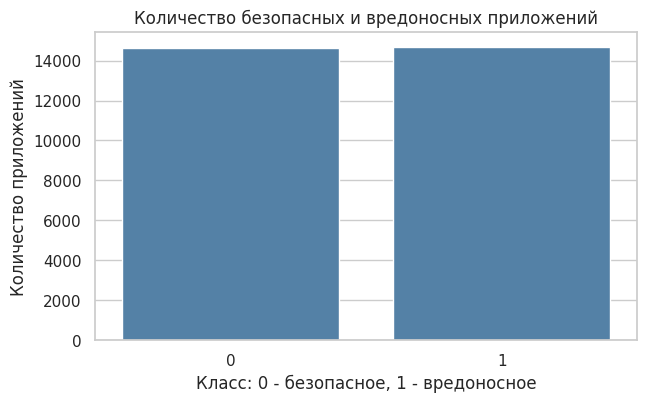

In [47]:
print(df["Result"].value_counts())
print("Доля каждого класса, %:")
print((df["Result"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Result", color="steelblue")
plt.title("Количество безопасных и вредоносных приложений")
plt.xlabel("Класс: 0 - безопасное, 1 - вредоносное")
plt.ylabel("Количество приложений")
plt.show()

**Вывод:** безопасных и вредоносных приложений в выборке примерно поровну.

### 3.6. Самые распространённые разрешения

В столбцах с разрешениями стоят 0 и 1, поэтому среднее значение столбца - это доля приложений, запрашивающих разрешение. Найдём десять наиболее часто встречающихся разрешений.

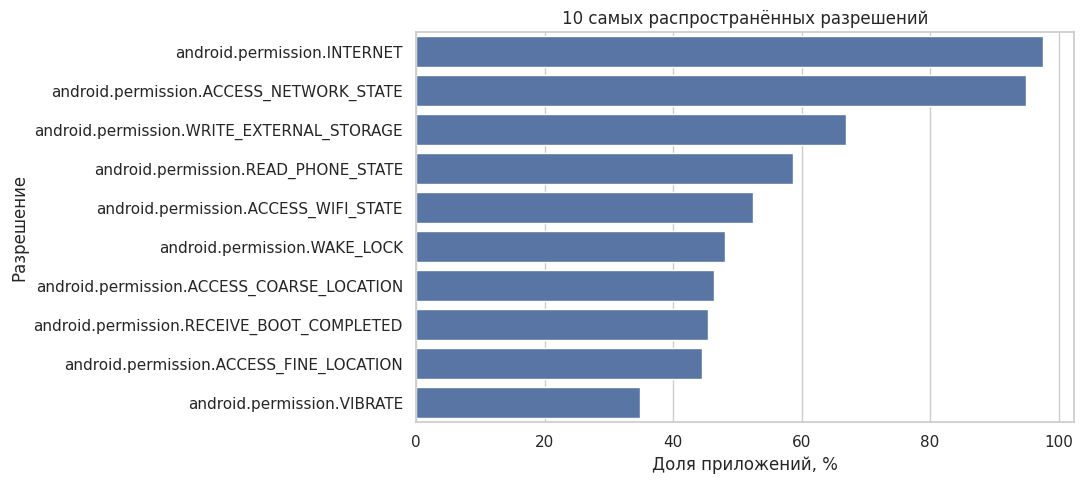

Чаще всего встречается: android.permission.INTERNET
Его запрашивают 97.5 % приложений.


In [48]:
top_permissions = df[permission_cols].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=top_permissions.values * 100, y=top_permissions.index)
plt.title("10 самых распространённых разрешений")
plt.xlabel("Доля приложений, %")
plt.ylabel("Разрешение")
plt.tight_layout()
plt.show()

print("Чаще всего встречается:", top_permissions.index[0])
print("Его запрашивают", round(top_permissions.iloc[0] * 100, 1), "% приложений.")

**Вывод:** чаще всего приложения запрашивают доступ к интернету `INTERNET` - **97,5%** и к информации о состоянии сети `ACCESS_NETWORK_STATE` - **94,9%**.

Эти разрешения распространены почти у всех приложений, поэтому сами по себе мало говорят о том, опасна ли программа.

### 3.7. Сколько разрешений запрашивает одно приложение?

Посчитаем для каждого приложения количество запрошенных разрешений. Сравним это число для безопасных и вредоносных программ.

          count   mean   std  min  25%   50%   75%   max
Result                                                  
0       14632.0   8.06  6.76  0.0  3.0   6.0  10.0  65.0
1       14700.0  10.83  4.28  0.0  8.0  10.0  13.0  52.0


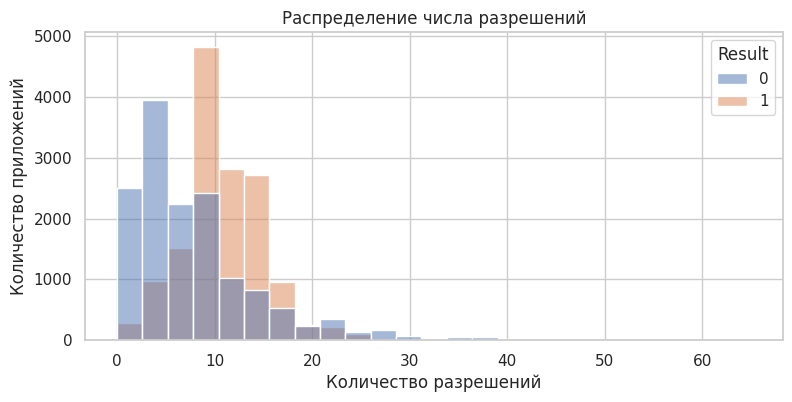

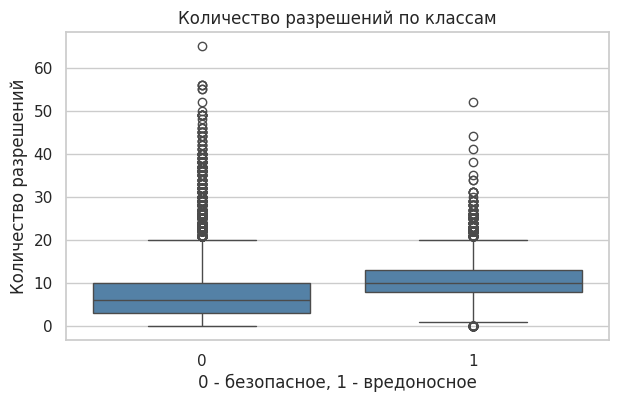

Среднее число разрешений у безопасных приложений: 8.06
Среднее число разрешений у вредоносных приложений: 10.83


In [49]:
df["permission_count"] = df[permission_cols].sum(axis=1)

print(df.groupby("Result")["permission_count"].describe().round(2))

plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="permission_count", hue="Result", bins=25, palette="deep")
plt.title("Распределение числа разрешений")
plt.xlabel("Количество разрешений")
plt.ylabel("Количество приложений")
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Result", y="permission_count", color="steelblue")
plt.title("Количество разрешений по классам")
plt.xlabel("0 - безопасное, 1 - вредоносное")
plt.ylabel("Количество разрешений")
plt.show()

avg = df.groupby("Result")["permission_count"].mean()
print("Среднее число разрешений у безопасных приложений:", round(avg.loc[0], 2))
print("Среднее число разрешений у вредоносных приложений:", round(avg.loc[1], 2))

**Вывод:** безопасные приложения запрашивают в среднем 8 разрешений, а вредоносные - 10. Значит, в этом наборе вредоносные приложения обычно запрашивают больше разрешений.

Однако распределения пересекаются: существуют безопасные приложения с большим количеством разрешений и вредоносные с небольшим. Поэтому только по числу разрешений определять вредоносность нельзя.

### 3.8. Какие разрешения больше всего отличаются между классами?

Сравним, как часто каждое разрешение встречается среди безопасных и вредоносных приложений. Чем больше разница, тем интереснее признак для дальнейшего изучения.

,"Безопасные, %","Вредоносные, %"
android.permission.READ_PHONE_STATE,23.0,94.3
android.permission.RECEIVE_BOOT_COMPLETED,20.6,70.3
android.permission.ACCESS_COARSE_LOCATION,24.8,67.8
android.permission.ACCESS_FINE_LOCATION,24.2,64.8
com.google.android.c2dm.permission.RECEIVE,41.2,1.4
com.android.launcher.permission.INSTALL_SHORTCUT,2.9,39.9
android.permission.GET_TASKS,6.9,39.8
android.permission.SYSTEM_ALERT_WINDOW,5.9,31.5
android.permission.ACCESS_WIFI_STATE,42.0,63.0
com.android.vending.BILLING,21.9,4.6


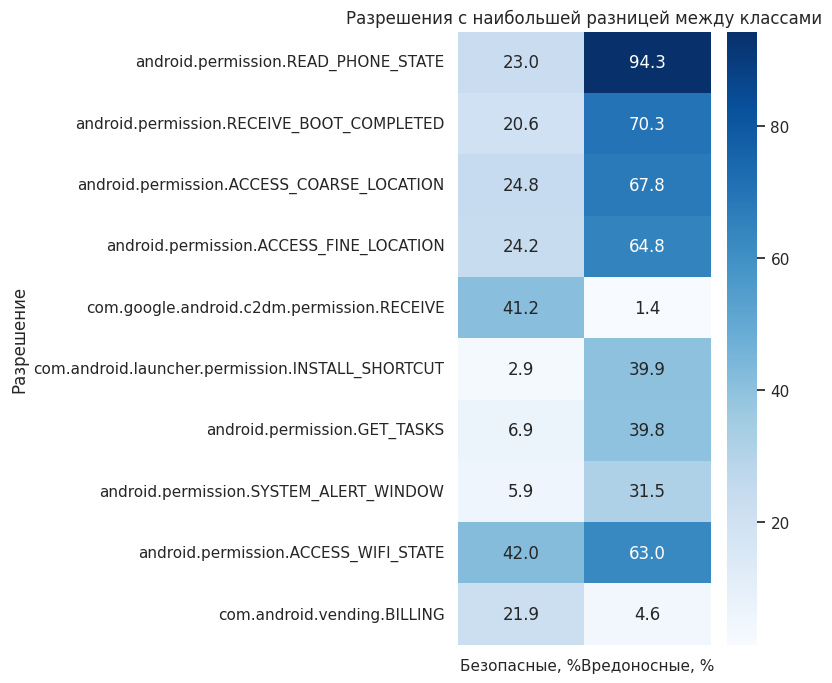

In [50]:
# среднее значение для каждого разрешения в двух классах
rates = df.groupby("Result")[permission_cols].mean()

# разница между вредоносными и безопасными приложениями
importance = (rates.loc[1] - rates.loc[0]).abs().sort_values(ascending=False)
important_permissions = importance.head(10).index

# доля приложений с каждым разрешением
comparison = rates[important_permissions].T * 100
comparison.columns = ["Безопасные, %", "Вредоносные, %"]

display(comparison.round(1))

plt.figure(figsize=(8, 7))
sns.heatmap(comparison, annot=True, fmt=".1f", cmap="Blues")
plt.title("Разрешения с наибольшей разницей между классами")
plt.ylabel("Разрешение")
plt.tight_layout()
plt.show()

**Вывод:** самая большая разница наблюдается у `READ_PHONE_STATE`: его запрашивают **94,3% вредоносных** и **23,0% безопасных** приложений.

Разрешение `RECEIVE_BOOT_COMPLETED` тоже встречается заметно чаще у вредоносных - **70,3% против 20,6%**.

При этом есть и обратные примеры: разрешение `com.google.android.c2dm.permission.RECEIVE` чаще встречается у безопасных приложений - **41,2% против 1,4%**.

### 3.9. Разрешения, связанные с личными данными

Отдельно посмотрим на разрешения для работы с SMS, контактами, микрофоном и камерой. С точки зрения ИБ они наиболее интересны, потому что предоставляют доступ к чувствительной информации или функциям устройства.

,Безопасные,Вредоносные
android.permission.READ_SMS,1.0,9.3
android.permission.SEND_SMS,1.9,11.8
android.permission.READ_CONTACTS,5.9,19.4
android.permission.RECORD_AUDIO,7.8,3.9
android.permission.CAMERA,16.9,12.8


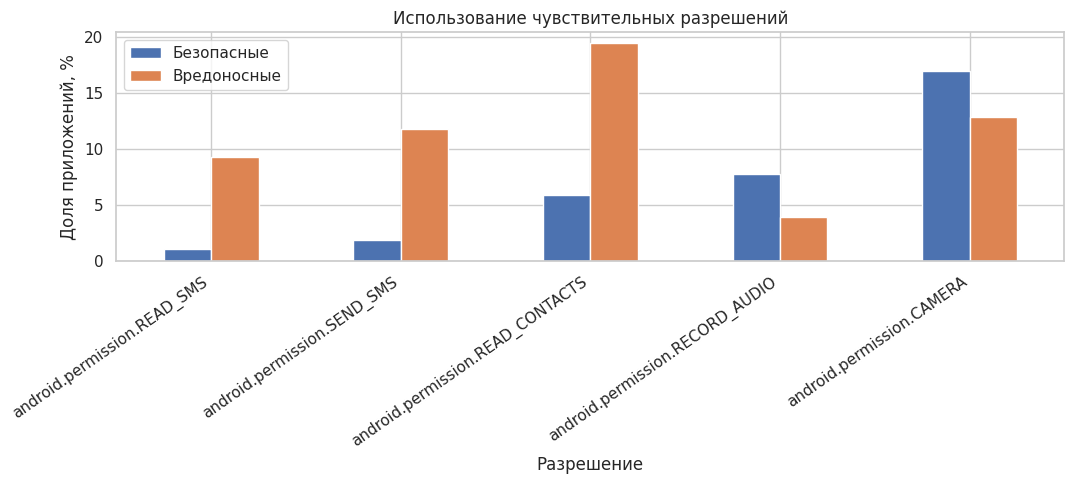

In [51]:
sensitive_permissions = [
    "android.permission.READ_SMS",
    "android.permission.SEND_SMS",
    "android.permission.READ_CONTACTS",
    "android.permission.RECORD_AUDIO",
    "android.permission.CAMERA"
]

sensitive_stats = df.groupby("Result")[sensitive_permissions].mean().T * 100
sensitive_stats.columns = ["Безопасные", "Вредоносные"]

display(sensitive_stats.round(1))

sensitive_stats.plot(kind="bar", figsize=(11, 5))
plt.title("Использование чувствительных разрешений")
plt.xlabel("Разрешение")
plt.ylabel("Доля приложений, %")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Вывод:** среди вредоносных приложений чаще встречаются:
 - разрешения на чтение SMS - 9,3% против 1,0%,
 - отправку SMS - 11,8% против 1,9%  
 - чтение контактов - 19,4% против 6,0%.

Но не каждое разрешение встречается чаще у вредоносных программ: например, `CAMERA` и `RECORD_AUDIO` в этих данных чаще запрашиваются безопасными приложениями. Сам факт наличия разрешения ещё не доказывает, что программа вредоносная.

### 3.10. Корреляции между разрешениями

Посмотрим, какие разрешения часто встречаются вместе. Для этого построим матрицу корреляций для десяти разрешений, которрые расмматривали ранее

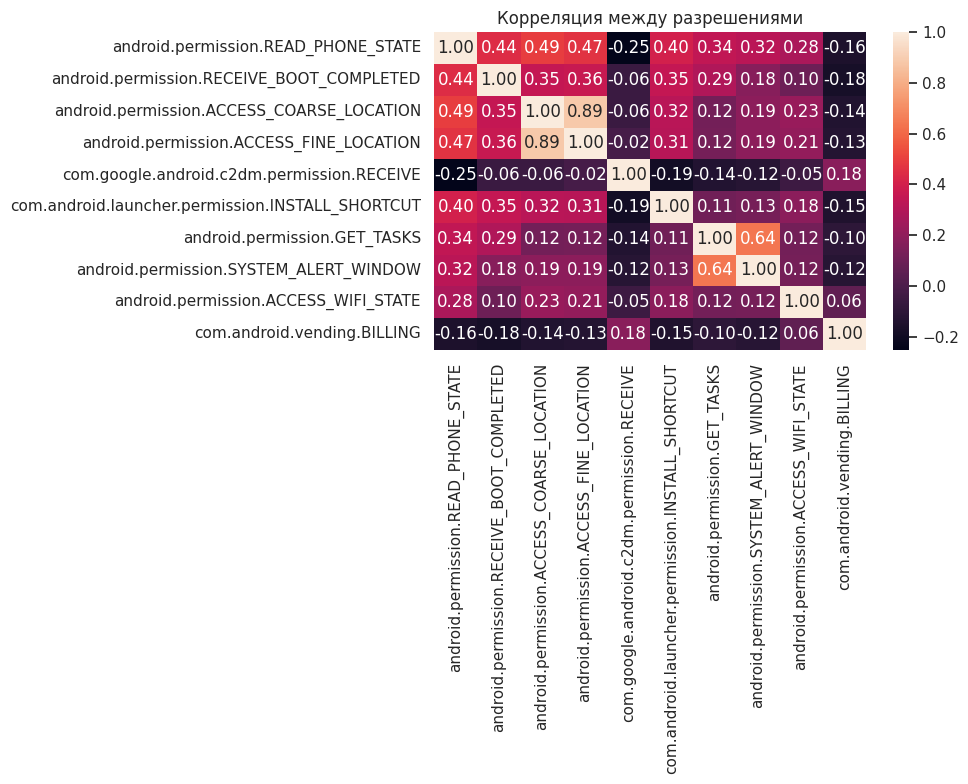

In [52]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[important_permissions].corr(), annot=True, fmt=".2f")
plt.title("Корреляция между разрешениями")
plt.tight_layout()
plt.show()

**Вывод:** у `ACCESS_COARSE_LOCATION` и `ACCESS_FINE_LOCATION` высокая положительная корреляция - около 0,89. Это означает, что приложения часто запрашивают оба разрешения вместе. При будущем обучении можно проверить, не передают ли эти два признака почти одинаковую информацию. Корреляция не означает, что одно разрешение вызывает другое.

## 4. Итоги



In [55]:
print("Приложений в наборе:", len(df))
print("Признаков-разрешений:", len(permission_cols))
print("Безопасных приложений:", (df["Result"] == 0).sum())
print("Вредоносных приложений:", (df["Result"] == 1).sum())
print("Пропусков:", df.isna().sum().sum())
print("Повторяющихся строк:", df.duplicated().sum())
print("Самое частое разрешение:", top_permissions.index[0])
print("Разрешение с наибольшей разницей между классами:", importance.index[0])
print("Среднее число разрешений у безопасных приложений:", round(avg.loc[0], 2))
print("Среднее число разрешений у вредоносных приложений:", round(avg.loc[1], 2))

Приложений в наборе: 29332
Признаков-разрешений: 86
Безопасных приложений: 14632
Вредоносных приложений: 14700
Пропусков: 0
Повторяющихся строк: 21841
Самое частое разрешение: android.permission.INTERNET
Разрешение с наибольшей разницей между классами: android.permission.READ_PHONE_STATE
Среднее число разрешений у безопасных приложений: 8.06
Среднее число разрешений у вредоносных приложений: 10.83


## Общие выводы

1. В наборе **29 332 приложения** и **86 признаков**. Пропусков нет, а доля безопасных и вредоносных приложений почти одинаковая: **49,9%** и **50,1%**.
2. Чаще всего приложения запрашивают интернет **97,5%**. Такое разрешение есть почти у всех, поэтому оно не очень полезно для простого отличия двух классов.
3. Вредоносные приложения в среднем запрашивают **10,83 разрешения**, а безопасные - **8,06**.
4. Наиболее заметные различия между классами наблюдаются у READ_PHONE_STATE, RECEIVE_BOOT_COMPLETED и некоторых разрешений для определения местоположения. Чтение и отправка SMS тоже чаще встречаются у вредоносных приложений.
5. У двух разрешений на местоположение ACCESS_COARSE_LOCATION и ACCESS_FINE_LOCATION корреляция примерно **0,89**, значит их часто запрашивают вместе.
6. В таблице много повторяющихся строк - **21 841**. Кроме того, одни и те же наборы разрешений иногда встречаются у приложений с разными метками класса - **96** таких наборов. Поэтому по одним разрешениям нельзя всегда точно определить вредоносность приложения.